In [1]:
import anndata as ad
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
import pandas as pd
import os
import seaborn as sns
from plotting_utils import cm_to_inches, setup_plotting_environment
from unicode_utils import introduce_greek_letters
setup_plotting_environment()

plot_folder = "plots/UMAP_inspection"
os.makedirs(plot_folder, exist_ok=True)

In [2]:
# ------- CRITICAL -------
alt_flag = False # use an alternative cell type set
# ------- CRITICAL -------
if not alt_flag:
    from constants import CELL_TYPE_COLORS, ALL_CELL_TYPES
else:
    from constants import CELL_TYPE_COLORS_ALT, ALL_CELL_TYPES_ALT
    ALL_CELL_TYPES = ALL_CELL_TYPES_ALT
    CELL_TYPE_COLORS = CELL_TYPE_COLORS_ALT
    
if not alt_flag:
    relevant_cell_types = [
        "CD4",
        "CD8",
        "B",
        "CD56-bright NK",
        "Treg",
        "MAIT",
        "CD14 Mono",
        "CD16 Mono",
        "CD56-dim NK",
        "NKT",
        "cDC",
        "pDC",
        "other",
        "ILC",
        "HSPC",
        "Plasmablast",
        "Platelet",
    ]
    relevant_cell_type_conversion = {
        "B": "B cell",
        "CD4": "CD4 T cell",
        "CD8": "CD8 T cell",
        "Treg": "Treg",
        "MAIT": "MAIT",
        "NKT": "NKT",
        "cDC": "cDC",
        "pDC": "pDC",
        "CD56-bright NK": "NK CD56hi",
        "CD56-dim NK": "NK CD56low",
        "CD14 Mono": "CD14 Mono",
        "CD16 Mono": "CD16 Mono",
        "HSPC": "HSPC",
        "other": "granulocyte",
        "ILC": "ILC",
        "Plasmablast": "Plasmablast",
        "Platelet": "Platelet",
    }
else:
    relevant_cell_types = [
        "CD4 Naive",
        "CD4 Memory",
        "CD8 Naive",
        "CD8 Memory",
        "B Naive",
        "B Intermediate Memory",
        "Treg",
        "MAIT",
        "CD14 Mono",
        "CD16 Mono",
        "CD56-bright NK",
        "CD56-dim NK",
        "NKT",
        "cDC",
        "pDC",
        "other",
        "ILC",
        "HSPC",
    ]
    relevant_cell_type_conversion = {
        "CD4 Naive": "CD4 Naive",
        "CD4 Memory": "CD4 Memory",
        "CD8 Naive": "CD8 Naive",
        "CD8 Memory": "CD8 Memory",
        "B Naive": "B Naive",
        "B Intermediate Memory": "B Intermediate",
        "Treg": "Treg",
        "MAIT": "MAIT",
        "NKT": "NKT",
        "cDC": "cDC",
        "pDC": "pDC",
        "CD56-bright NK": "NK CD56hi",
        "CD56-dim NK": "NK CD56low",
        "CD14 Mono": "CD14 Mono",
        "CD16 Mono": "CD16 Mono",
        "HSPC": "HSPC",
        "other": "granulocyte",
        "ILC": "ILC",
    }    

In [3]:
# info on cytokines
cytokine_info_order = pd.read_excel("../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="suggested_order")
CYTOKINE_ORDER = list(cytokine_info_order["name"])

In [4]:
umap_file = "../../data/adata_umap_compressed.h5ad"
umap_data = ad.read_h5ad(umap_file)
umap_data.obs['donor'] = umap_data.obs['donor'].str.replace("Donor", "D")

In [5]:
cell_metadata = pd.read_csv("../../data/10M_Parse_PBMC_cytokines_cell_metadata.csv")
cell_metadata['UMIs'] = np.log10(np.exp(cell_metadata['log1p_total_counts'])-1)
cell_metadata['detected_genes'] = np.log10(np.exp(cell_metadata['log1p_n_genes_by_counts'])-1)
cell_metadata_sampled = cell_metadata.sample(n=200000, random_state=42)

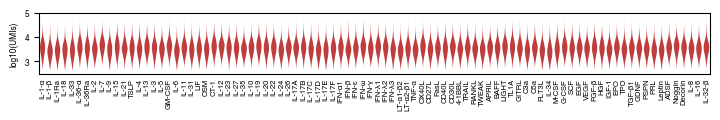

In [66]:
order = [c for c in CYTOKINE_ORDER if c in cell_metadata['cytokine'].unique()]

plt.close()
plt.figure(figsize=cm_to_inches((22, 2)))
sns.violinplot(
    data=cell_metadata,
    x="cytokine",
    y="UMIs",
    order=order,
    inner="stick",
    color='tab:red',
    edgecolor='none'
    )
plt.xticks(rotation=90)
plt.tick_params(axis='x', labelsize=5.5, length=0)
plt.xticks(np.arange(len(order)), [introduce_greek_letters(c) for c in order])
plt.xlabel("")
plt.ylabel("log10(UMIs)")
plt.ylim(2.5,5)
plt.savefig(os.path.join(plot_folder, "cytokine_vs_UMIs_violinplot.svg"), dpi=300)

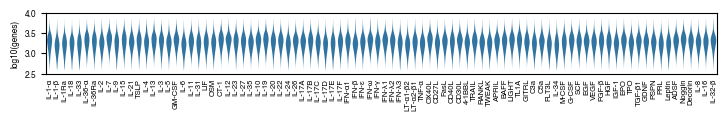

In [67]:
plt.close()
plt.figure(figsize=cm_to_inches((22, 2)))
sns.violinplot(
    data=cell_metadata,
    x="cytokine",
    y="detected_genes",
    order=order,
    inner="stick",
    color='tab:blue',
    edgecolor='none'
    )
plt.xticks(rotation=90)
plt.tick_params(axis='x', labelsize=5.5, length=0)
plt.xticks(np.arange(len(order)), [introduce_greek_letters(c) for c in order])
plt.xlabel("")
plt.ylim(2.5,4)
plt.ylabel("log10(genes)")
plt.savefig(os.path.join(plot_folder, "cytokine_vs_detected_genes_violinplot.svg"), dpi=300)

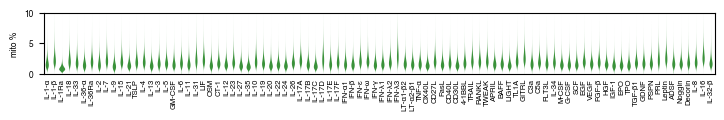

In [69]:
plt.close()
plt.figure(figsize=cm_to_inches((22, 2)))
sns.violinplot(
    data=cell_metadata,
    x="cytokine",
    y="pct_counts_MT",
    order=order,
    inner="stick",
    color='tab:green',
    edgecolor='none'
    )
plt.xticks(rotation=90)
plt.tick_params(axis='x', labelsize=5.5, length=0)
plt.xticks(np.arange(len(order)), [introduce_greek_letters(c) for c in order])
plt.xlabel("")
plt.ylabel("mito %")
plt.ylim(0,10)
plt.savefig(os.path.join(plot_folder, "cytokine_vs_pct_counts_MT_violinplot.svg"), dpi=300)

## Plot UMAP data

In [6]:
umap_data.obs.drop(columns=["cell_type"], inplace=True, errors="ignore")
if alt_flag:
    umap_data.obs['cell_type'] = umap_data.obs['cell_type_refined']
else:
    umap_data.obs['cell_type'] = umap_data.obs['cell_type_refined_coarse']
unique_cell_types = umap_data.obs['cell_type'].unique()
for cell_type in unique_cell_types:
    if not cell_type in relevant_cell_types:
        raise ValueError(f"Cell type {cell_type} not in relevant_cell_types")
umap_data.obs['cell_type'] = umap_data.obs['cell_type'].map(relevant_cell_type_conversion)

In [7]:
# --- Helper: HSL → HEX (0–360, 0–100, 0–100) ---
import colorsys

def hsl_to_hex(h, s, l):
    h = (h % 360) / 360.0
    s = max(0, min(s, 100)) / 100.0
    l = max(0, min(l, 100)) / 100.0
    r, g, b = colorsys.hls_to_rgb(h, l, s)  # note: colorsys uses HLS
    return "#{:02x}{:02x}{:02x}".format(int(round(r*255)), int(round(g*255)), int(round(b*255)))

In [8]:
# donor info - not really using this for now
DONOR_NAMES = [f"Donor{i+1}" for i in range(12)]
donor_metadata = pd.read_excel("../annotations/donor_metadata.xlsx")
donor_metadata["Donor number"] = donor_metadata["Donor number"].str.replace(" ", "")
donor_metadata.index = donor_metadata["Donor number"]
donor_metadata["age"] = 2024 - donor_metadata["Birth year"]
donor_metadata = donor_metadata.sort_values(by="Sex")
DONOR_NAMES = donor_metadata.index.tolist()
DONOR_NAMES = [d.replace("Donor", "D") for d in DONOR_NAMES]

palette = plt.get_cmap("tab20").colors  # 20 distinct colors
DONOR_COLORS = {donor: mcolors.to_hex(palette[i]) for i, donor in enumerate(DONOR_NAMES)}

In [9]:
# info on cytokines
cytokine_info = pd.read_excel("../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="all_cytokines")
cytokine_info["single_gene"] = cytokine_info["gene"].str.split(",").str[0]

cytokine_info_parse = cytokine_info[cytokine_info["parse_cytokine"]]
cytokine_info_order = pd.read_excel("../annotations/20250405_cytokine_info_with_functional_classification_LO.xlsx", index_col=0, sheet_name="suggested_order")

CYTOKINE_ORDER = list(cytokine_info_order["name"])
CYTOKINE_ORDER_WITH_PBS = ["PBS"] + CYTOKINE_ORDER
SINGLE_FAMILY_ORDER = cytokine_info_order["DEG_plot_family"].unique()

In [10]:
coordinates_by_cell_type = {
    "B cell": ((1,12),(-9, 4)),
    "CD4 T cell": ((0,23),(0,20)),
    "CD8 T cell": ((1, 23),(1,23)),
    "Treg": ((1, 21), (1, 15)),
    "MAIT": ((0.5,11),(2, 20)),
    "NKT": ((1,20), (1, 23)),
    "NK CD56hi": ((3,16), (10,25)),
    "NK CD56low": ((2.5, 17.5), (12, 25)),
#    "pDC": ((-3,12), (0,10)),
    "cDC": ((-6,4), (-3,18)),
    "CD14 Mono": ((-7.5,2.5),(0,20)),
    "CD16 Mono": ((-7.5,2.5),(3,17)),
    "HSPC": ((-2, 11),(0,23))
}

B cell
CD4 T cell
CD8 T cell
Treg
MAIT
NKT
NK CD56hi
NK CD56low
cDC
CD14 Mono
CD16 Mono
HSPC


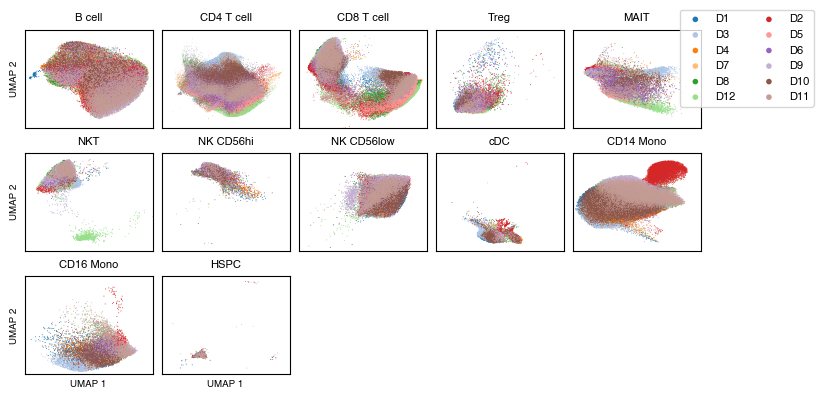

In [11]:
pbs_data = umap_data[umap_data.obs['cytokine'] == "PBS"]

# Plot UMAP colored by donor
max_points = 200000

fig, axes = plt.subplots(3, 5, figsize=cm_to_inches((18, 10)))
axes = axes.flatten()  # Convert to 1D array for easier indexing

for idx, cell_type in enumerate(ALL_CELL_TYPES):
    print(cell_type)
    if idx >= 15:  # Only plot first 16 cell types for 4x4 grid
        break
        
    ax = axes[idx]
    subset = pbs_data[pbs_data.obs['cell_type'] == cell_type]
    if len(subset) < 100:
        print(f"Skipping {cell_type} because it has less than 100 cells")
        continue
    
    # Subsample if needed
    downsampling_rate = max(len(subset) / max_points, 1)
    below_max_points = max(1.0, max_points / len(subset))
    if len(subset) > max_points:
        subset = subset[np.random.choice(len(subset), max_points, replace=False)]
    
    # Get UMAP coordinates
    umap_coords = subset.obsm['X_umap']
    
    # Calculate percentiles to exclude outliers
    # x_coords = umap_coords[:, 0]
    # y_coords = umap_coords[:, 1]
    # x_min, x_max = np.percentile(x_coords, [1 / max(below_max_points, 0.5), 100 - 1 / max(below_max_points, 0.5)])
    # y_min, y_max = np.percentile(y_coords, [1 / max(below_max_points, 0.5), 100 - 1 / max(below_max_points, 0.5)])
    
    # Plot each donor with different color
    for donor in DONOR_NAMES:
        mask = subset.obs['donor'] == donor
        if np.any(mask):
            ax.scatter(umap_coords[mask, 0], umap_coords[mask, 1], c=[DONOR_COLORS[donor]],
                       label=donor, alpha=1, s=0.15*min(below_max_points, 3), edgecolors="none", rasterized=True)
    
    # Set axis limits to exclude stray cells
    # x_range = x_max - x_min
    # x_mid = (x_max + x_min) / 2
    # ax.set_xlim(x_mid - x_range*0.7, x_mid + x_range*0.7)
    # y_range = y_max - y_min
    # y_mid = (y_max + y_min) / 2
    # ax.set_ylim(y_mid - y_range*0.7, y_mid + y_range*0.7)
    ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
    ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])
    
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Only label outer axes
    if idx // 5 == 2:  # Bottom row
        ax.set_xlabel('UMAP 1', fontsize=7)
    if idx % 5 == 0:  # Left column
        ax.set_ylabel('UMAP 2', fontsize=7)
    
    ax.set_title(f"{cell_type}", fontsize=8)
    ax.tick_params(labelsize=6)
    
# Hide unused subplots
for idx in range(len(ALL_CELL_TYPES), 15):
    axes[idx].set_visible(False)

# Add a single legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(0.95, 1), loc='upper left', fontsize=8, markerscale=6, ncol=2)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"UMAP_pbs_by_donor.svg"), dpi=400)

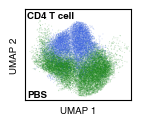

In [12]:
cell_type = "CD4 T cell"
donor_group_1 = ["D1", "D3", "D4", "D10"]
donor_group_2 = [donor for donor in DONOR_NAMES if donor not in donor_group_1]

max_points_per_donor = 2000

colors = ["forestgreen", "royalblue"]
fig, ax = plt.subplots(figsize=cm_to_inches((3.5, 3)))
for donor_group, color in zip([donor_group_2, donor_group_1], colors):
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    subset = subset[subset.obs['donor'].isin(donor_group)]
    subset = subset[subset.obs['cytokine'] == "PBS"]
    
    if len(subset) > max_points_per_donor:
        subset = subset[np.random.choice(len(subset), max_points_per_donor * len(donor_group), replace=False)]
        
    umap_coords = subset.obsm['X_umap']
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=[color],
                label=",".join(donor_group), alpha=0.25, s=0.5, edgecolors="none", rasterized=True)
            
# # Create a much finer grid
# ax.grid(True, linestyle='-', alpha=0.2, linewidth=0.3, which='major')
# ax.grid(True, linestyle=':', alpha=0.1, linewidth=0.2, which='minor')
# ax.minorticks_on()  # Enable minor ticks for finer grid
# ax.set_axisbelow(True)  # Ensure grid is behind the data points

ax.set_xlim(coordinates_by_cell_type[cell_type][0][0]+1.5, coordinates_by_cell_type[cell_type][0][1]-1.5)
ax.set_ylim(coordinates_by_cell_type[cell_type][1][0]+1.5, coordinates_by_cell_type[cell_type][1][1]-2.5)

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("UMAP 1", fontsize=7)
ax.set_ylabel("UMAP 2", fontsize=7)

ax.text(2, 16, "CD4 T cell", fontsize=7, fontweight="bold", color="black")
ax.text(2, 2, "PBS", fontsize=7, fontweight="bold", color="black")

# Add legend
#ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6, markerscale=8)
# plt.subplots_adjust(right=0.8)  # Make room for legend

# Enable interactive zoom and pan
plt.savefig(os.path.join(plot_folder, f"UMAP_CD4_T_cell_donor_groups.svg"), dpi=400)

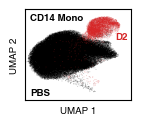

In [11]:
cell_type = "CD14 Mono"
donor_group_1 = ["D2"]
donor_group_2 = [donor for donor in DONOR_NAMES if donor not in donor_group_1]

max_points_per_donor = 5000

colors = ["black", DONOR_COLORS["D2"]]
fig, ax = plt.subplots(figsize=cm_to_inches((3.5, 3)))
for donor_group, color in zip([donor_group_2, donor_group_1], colors):
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    subset = subset[subset.obs['donor'].isin(donor_group)]
    subset = subset[subset.obs['cytokine'] == "PBS"]
    
    if len(subset) > max_points_per_donor:
        subset = subset[np.random.choice(len(subset), max_points_per_donor * len(donor_group), replace=False)]
        
    umap_coords = subset.obsm['X_umap']
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=[color],
                label=",".join(donor_group), alpha=0.25, s=0.5, edgecolors="none", rasterized=True)
            
# # Create a much finer grid
# ax.grid(True, linestyle='-', alpha=0.2, linewidth=0.3, which='major')
# ax.grid(True, linestyle=':', alpha=0.1, linewidth=0.2, which='minor')
# ax.minorticks_on()  # Enable minor ticks for finer grid
# ax.set_axisbelow(True)  # Ensure grid is behind the data points

ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("UMAP 1", fontsize=7)
ax.set_ylabel("UMAP 2", fontsize=7)

ax.text(-7, 17.5, "CD14 Mono", fontsize=7, fontweight="bold", color='black')
ax.text(-7, 1, "PBS", fontsize=7, fontweight="bold", color='black')
ax.text(1, 13.5, "D2", fontsize=7, fontweight="bold", color=DONOR_COLORS["D2"])

# Add legend
#ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6, markerscale=8)
#plt.subplots_adjust(right=0.8)  # Make room for legend

# Enable interactive zoom and pan
plt.savefig(os.path.join(plot_folder, f"UMAP_CD14_D2_PBS.svg"), dpi=400)

1542.4545454545455 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] IL-32-beta
842.0 ['D2'] IL-32-beta
1203.909090909091 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] IL-2
729.0 ['D2'] IL-2
1344.6363636363637 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] IFN-gamma
1312.0 ['D2'] IFN-gamma
1702.1818181818182 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] IL-4
1456.0 ['D2'] IL-4
1207.3636363636363 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] IL-10
1311.0 ['D2'] IL-10
1187.1818181818182 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] VEGF
867.0 ['D2'] VEGF
1370.090909090909 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] M-CSF
1313.0 ['D2'] M-CSF
1571.3636363636363 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D9', 'D10', 'D11'] GM-CSF
1444.0 ['D2'] GM-CSF
1338.6363636363637 ['D1', 'D3', 'D4', 'D7', 'D8', 'D12', 'D5', 'D6', 'D

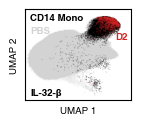

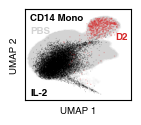

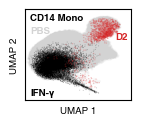

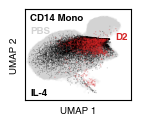

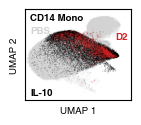

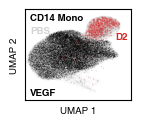

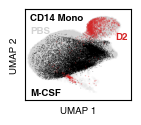

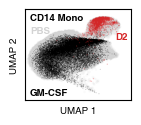

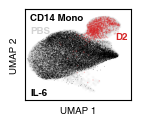

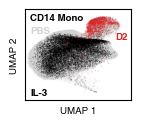

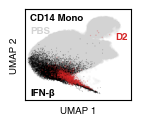

In [13]:
cell_type = "CD14 Mono"
for test_cytokine in ["IL-32-beta", "IL-2", "IFN-gamma", "IL-4", "IL-10", "VEGF", "M-CSF", "GM-CSF", "IL-6", "IL-3", "IFN-beta"]:
    donor_group_1 = ["D2"]
    donor_group_2 = [donor for donor in DONOR_NAMES if donor not in donor_group_1]
    
    colors = ["black", DONOR_COLORS["D2"]]
    fig, ax = plt.subplots(figsize=cm_to_inches((3.5, 3)))
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    subset = subset[subset.obs['cytokine'] == "PBS"]
    subset = subset[np.random.choice(len(subset), 50000, replace=False)]
    umap_coords = subset.obsm['X_umap']
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="lightgray",
        label=",".join(donor_group), alpha=0.1, s=3, edgecolors="none", rasterized=True)
    ax.text(-7, 14.75, "PBS", fontsize=7, fontweight="bold", color='lightgray')
    
    max_points_per_donor = 5000
    for donor_group, color in zip([donor_group_2, donor_group_1], colors):
        subset = umap_data[umap_data.obs['cell_type'] == cell_type]
        subset = subset[subset.obs['donor'].isin(donor_group)]
        subset = subset[subset.obs['cytokine'] == test_cytokine]
        
        print(len(subset)/len(donor_group), donor_group, test_cytokine)
        if len(subset) > max_points_per_donor * len(donor_group):
            subset = subset[np.random.choice(len(subset), max_points_per_donor * len(donor_group), replace=False)]
            
        umap_coords = subset.obsm['X_umap']
        if "D2" in donor_group:
            s=1
        else:
            s=0.5
        ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=[color],
                    label=",".join(donor_group), alpha=0.25, s=s, edgecolors="none", rasterized=True)

    # # Create a much finer grid
    # ax.grid(True, linestyle='-', alpha=0.2, linewidth=0.3, which='major')
    # ax.grid(True, linestyle=':', alpha=0.1, linewidth=0.2, which='minor')
    # ax.minorticks_on()  # Enable minor ticks for finer grid
    # ax.set_axisbelow(True)  # Ensure grid is behind the data points

    ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
    ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])

    ax.set_xticks([])
    ax.set_yticks([])

    ax.set_xlabel("UMAP 1", fontsize=7)
    ax.set_ylabel("UMAP 2", fontsize=7)

    ax.text(-7, 17.5, "CD14 Mono", fontsize=7, fontweight="bold", color='black')
    ax.text(-7, 1, introduce_greek_letters(test_cytokine), fontsize=7, fontweight="bold", color='black')
    ax.text(1, 13.5, "D2", fontsize=7, fontweight="bold", color=DONOR_COLORS["D2"])

    # Add legend
    #ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6, markerscale=8)
    #plt.subplots_adjust(right=0.8)  # Make room for legend

    plt.savefig(os.path.join(plot_folder, f"UMAP_cDC_D2_{test_cytokine}.svg"), dpi=400)

In [25]:
# cell_type = "CD14 Mono"
# donor_group_1 = ["D2"]
# donor_group_2 = [donor for donor in DONOR_NAMES if donor not in donor_group_1]

# max_points_per_donor = 5000

# colors = ["black", DONOR_COLORS["D2"]]
# fig, ax = plt.subplots(figsize=cm_to_inches((4, 3)))
# for donor_group, color in zip([donor_group_2, donor_group_1], colors):
#     subset = umap_data[umap_data.obs['cell_type'] == cell_type]
#     subset = subset[subset.obs['donor'].isin(donor_group)]
#     subset = subset[subset.obs['cytokine'] == "IL-32-beta"]
    
#     if len(subset) > max_points_per_donor * len(donor_group):
#         subset = subset[np.random.choice(len(subset), max_points_per_donor * len(donor_group), replace=False)]
        
#     umap_coords = subset.obsm['X_umap']
#     ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=[color],
#                 label=",".join(donor_group), alpha=0.25, s=0.5, edgecolors="none", rasterized=True)
            
# # # Create a much finer grid
# # ax.grid(True, linestyle='-', alpha=0.2, linewidth=0.3, which='major')
# # ax.grid(True, linestyle=':', alpha=0.1, linewidth=0.2, which='minor')
# # ax.minorticks_on()  # Enable minor ticks for finer grid
# # ax.set_axisbelow(True)  # Ensure grid is behind the data points

# ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
# ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])

# ax.set_xticks([])
# ax.set_yticks([])

# ax.set_xlabel("UMAP 1", fontsize=7)
# ax.set_ylabel("UMAP 2", fontsize=7)

# ax.text(-7, 17.5, "CD14 Mono", fontsize=7, fontweight="bold", color='black')
# ax.text(-7, 1, introduce_greek_letters("IL-32-beta"), fontsize=7, fontweight="bold", color='black')
# ax.text(1, 13.5, "D2", fontsize=7, fontweight="bold", color=DONOR_COLORS["D2"])

# # Add legend
# #ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6, markerscale=8)
# plt.subplots_adjust(right=0.8)  # Make room for legend

# # Enable interactive zoom and pan
# plt.savefig(os.path.join(plot_folder, f"UMAP_CD14_D2_IL32.svg"), dpi=400)

In [24]:
# cell_type = "CD14 Mono"
# donor_group_1 = ["D2"]
# donor_group_2 = [donor for donor in DONOR_NAMES if donor not in donor_group_1]

# max_points_per_donor = 5000

# colors = ["black", DONOR_COLORS["D2"]]
# fig, ax = plt.subplots(figsize=cm_to_inches((4, 3)))
# for donor_group, color in zip([donor_group_2, donor_group_1], colors):
#     subset = umap_data[umap_data.obs['cell_type'] == cell_type]
#     subset = subset[subset.obs['donor'].isin(donor_group)]
#     subset = subset[subset.obs['cytokine'] == "GM-CSF"]
    
#     if len(subset) > max_points_per_donor * len(donor_group):
#         subset = subset[np.random.choice(len(subset), max_points_per_donor * len(donor_group), replace=False)]
        
#     umap_coords = subset.obsm['X_umap']
#     ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=[color],
#                 label=",".join(donor_group), alpha=0.25, s=0.5, edgecolors="none", rasterized=True)
            
# # # Create a much finer grid
# # ax.grid(True, linestyle='-', alpha=0.2, linewidth=0.3, which='major')
# # ax.grid(True, linestyle=':', alpha=0.1, linewidth=0.2, which='minor')
# # ax.minorticks_on()  # Enable minor ticks for finer grid
# # ax.set_axisbelow(True)  # Ensure grid is behind the data points

# ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
# ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])

# ax.set_xticks([])
# ax.set_yticks([])

# ax.set_xlabel("UMAP 1", fontsize=7)
# ax.set_ylabel("UMAP 2", fontsize=7)

# ax.text(-7, 17.5, "CD14 Mono", fontsize=7, fontweight="bold", color='black')
# ax.text(-7, 1, introduce_greek_letters("IL-32-beta"), fontsize=7, fontweight="bold", color='black')
# ax.text(1, 13.5, "D2", fontsize=7, fontweight="bold", color=DONOR_COLORS["D2"])

# # Add legend
# #ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=6, markerscale=8)
# plt.subplots_adjust(right=0.8)  # Make room for legend

# # Enable interactive zoom and pan
# plt.savefig(os.path.join(plot_folder, f"UMAP_CD14_D2_GM-CSF.svg"), dpi=400)

B cell
CD4 T cell
CD8 T cell
Treg
MAIT
NKT
NK CD56hi
NK CD56low
cDC
CD14 Mono
CD16 Mono
HSPC


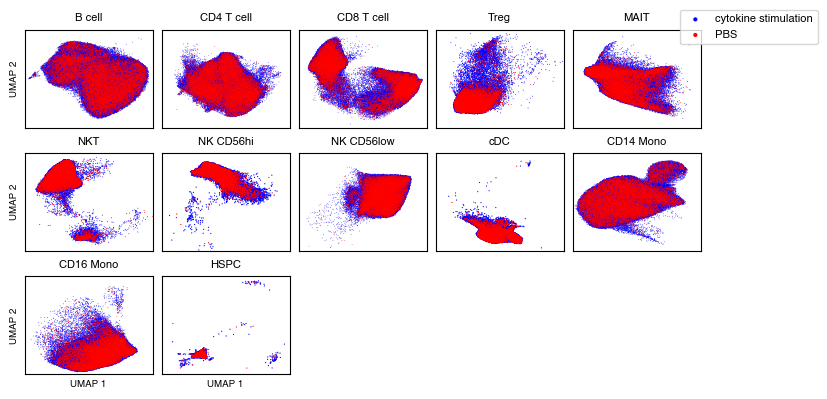

In [15]:
pbs_data = umap_data[umap_data.obs['cytokine'] == "PBS"]
other_data = umap_data[umap_data.obs['cytokine'] != "PBS"]

max_points_pbs = 20000
# Create a 5x3 grid for all cell types
fig, axes = plt.subplots(3, 5, figsize=cm_to_inches((18, 10)))
axes = axes.flatten()  # Convert to 1D array for easier indexing

for idx, cell_type in enumerate(ALL_CELL_TYPES):
    print(cell_type)
    if idx >= 15:  # Only plot first 16 cell types for 4x4 grid
        break
        
    ax = axes[idx]
    subset_pbs = pbs_data[pbs_data.obs['cell_type'] == cell_type]
    if len(subset_pbs) < 100:
        print(f"Skipping {cell_type} because it has less than 100 cells")
        continue
    subset_other = other_data[other_data.obs['cell_type'] == cell_type]
    if len(subset_other) < 100:
        print(f"Skipping {cell_type} because it has less than 100 cells")
        continue
    
    # Subsample if needed
    downsampling_rate = max(len(subset_pbs) / max_points_pbs, 1)
    below_max_points = max(1.0, max_points_pbs / len(subset_pbs))
    if len(subset_pbs) > max_points_pbs:
        subset_pbs = subset_pbs[np.random.choice(len(subset_pbs), max_points_pbs, replace=False)]
    if len(subset_other) > len(subset_pbs)*5:
        subset_other = subset_other[np.random.choice(len(subset_other), len(subset_pbs)*5, replace=False)]
    
    # Get UMAP coordinates
    umap_coords_pbs = subset_pbs.obsm['X_umap']
    umap_coords_other = subset_other.obsm['X_umap']
    
    ax.scatter(umap_coords_other[:, 0], umap_coords_other[:, 1], c=["blue"],
               label="cytokine stimulation", alpha=1, s=0.25*min(below_max_points, 3), edgecolors="none", rasterized=True)
    ax.scatter(umap_coords_pbs[:, 0], umap_coords_pbs[:, 1], c=["red"],
               label="PBS", alpha=1, s=0.25*min(below_max_points, 3), edgecolors="none", rasterized=True)
    
    ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
    ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])
    
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Only label outer axes
    if idx // 5 == 2:  # Bottom row
        ax.set_xlabel('UMAP 1', fontsize=7)
    if idx % 5 == 0:  # Left column
        ax.set_ylabel('UMAP 2', fontsize=7)
    
    ax.set_title(f"{cell_type}", fontsize=8)
    ax.tick_params(labelsize=6)
    
# Hide unused subplots
for idx in range(len(ALL_CELL_TYPES), 15):
    axes[idx].set_visible(False)

# Add a single legend for the entire figure
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, bbox_to_anchor=(0.95, 1), loc='upper left', fontsize=8, markerscale=6)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"UMAP_pbs_other_cell_types.svg"), dpi=300)

In [16]:
distances_by_cell_type = {}
for idx, cell_type in enumerate(ALL_CELL_TYPES):
    if idx >= 16:  # Only plot first 16 cell types for 4x4 grid
        break
    print(cell_type)
    adata_cell_type = umap_data[umap_data.obs['cell_type'] == cell_type]

    # get mean of PBS
    x_coords_pbs = adata_cell_type[adata_cell_type.obs['cytokine'] == "PBS"].obsm['X_umap'][:, 0]
    y_coords_pbs = adata_cell_type[adata_cell_type.obs['cytokine'] == "PBS"].obsm['X_umap'][:, 1]
    x_mean_pbs = x_coords_pbs.mean()
    y_mean_pbs = y_coords_pbs.mean()

    # get range of PBS
    x_min_pbs, x_max_pbs = np.percentile(x_coords_pbs, [1, 99])
    y_min_pbs, y_max_pbs = np.percentile(y_coords_pbs, [1, 99])
    range_x_pbs = x_max_pbs - x_min_pbs
    range_y_pbs = y_max_pbs - y_min_pbs
    distances_by_cytokine = {}
    for cytokine in CYTOKINE_ORDER:
        x_coords_cyto = adata_cell_type[adata_cell_type.obs['cytokine'] == cytokine].obsm['X_umap'][:, 0]
        y_coords_cyto = adata_cell_type[adata_cell_type.obs['cytokine'] == cytokine].obsm['X_umap'][:, 1]
        x_mean_cyto = x_coords_cyto.mean()
        y_mean_cyto = y_coords_cyto.mean()
        
        distances_by_cytokine[cytokine] = np.sqrt((x_mean_cyto - x_mean_pbs)**2 + (y_mean_cyto - y_mean_pbs)**2)
    distances_by_cytokine = pd.Series(distances_by_cytokine).sort_values(ascending=False)
    distances_by_cell_type[cell_type] = distances_by_cytokine
distances_by_cell_type = pd.DataFrame(distances_by_cell_type)
distances_by_cell_type_raw = distances_by_cell_type.copy()
distances_by_cell_type = distances_by_cell_type.div(distances_by_cell_type.max(axis=0), axis=1)
large_dist = distances_by_cell_type > 0.33

B cell
CD4 T cell
CD8 T cell
Treg
MAIT
NKT
NK CD56hi
NK CD56low
cDC
CD14 Mono
CD16 Mono
HSPC


In [17]:
allowed_cytokines = large_dist[large_dist.sum(axis=1)>1].index.tolist()
allowed_cytokines = allowed_cytokines + ["CD40L", "TPO"]

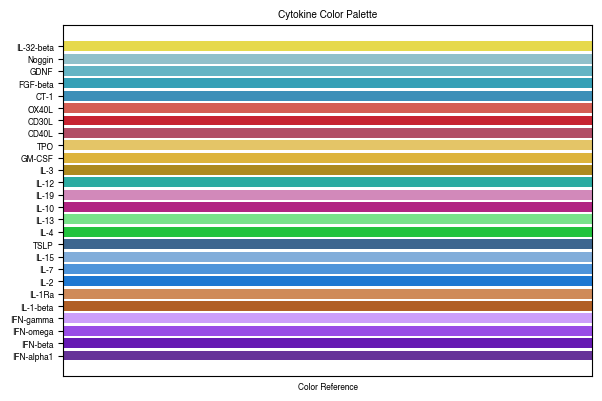

In [18]:

# --- Family-based HSL assignments (easy to tweak) ---
cytokine_colors_hsl = {
    # Interferons (violet/purple)
    "IFN-alpha1": (270, 50, 40),
    "IFN-beta":   (270, 75, 40),
    "IFN-omega":  (270, 75, 60),
    "IFN-gamma":  (270, 90, 80), 

    # IL-1 family (warm clay)
    "IL-1-beta":  (25, 65, 42),
    "IL-1Ra":     (25, 55, 58),

    # γc axis — royal blue set
    "IL-2":       (210, 75, 47),
    "IL-7":       (210, 65, 58),
    "IL-15":      (210, 55, 68),
    "TSLP":       (210, 40, 40),

    # Th2 pair (greens)
    "IL-4":       (130, 70, 45),
    "IL-13":      (130, 65, 68),

    # IL-10 family (pinks/magenta)
    "IL-10": (320, 65, 42),     
    "IL-19": (320, 45, 68),

    # IL-12 family (teal/blue-teal)
    "IL-12":      (175, 60, 42),

    # Hematopoietic growth (ambers/golds)
    "IL-3":       (45, 70, 40),
    "GM-CSF":     (45, 70, 55),
    "TPO":        (45, 70, 65),

    # Ligands
    "CD40L":      (345, 40, 50),
    "CD30L":      (355, 70, 46),
    "OX40L":      (365, 60, 58),

    # Growth & development factors (cyan/teal)
    "CT-1":       (200, 50, 48),
    "FGF-beta":   (190, 55, 46),
    "GDNF":       (190, 45, 58),
    "Noggin":     (190, 35, 68),

    # Distinct TNF-like
    "IL-32-beta": (55, 75, 60),
}

# --- Convert to HEX for immediate use ---
cytokine_colors_hex = {k: hsl_to_hex(*v) for k, v in cytokine_colors_hsl.items()}

# Create a color bar/legend showing all cytokine colors
fig, ax = plt.subplots(figsize=(6, 4))

# Get all cytokines that have colors defined
cytokines = list(cytokine_colors_hex.keys())
colors = list(cytokine_colors_hex.values())

# Create horizontal bars
y_positions = range(len(cytokines))
bars = ax.barh(y_positions, [1] * len(cytokines), color=colors, height=0.8)

# Customize the plot
ax.set_yticks(y_positions)
ax.set_yticklabels(cytokines)
ax.set_xlabel('Color Reference')
ax.set_title('Cytokine Color Palette')
ax.set_xlim(0, 1)

# Remove x-axis ticks and labels since we just want to show colors
ax.set_xticks([])

# Adjust layout to prevent label cutoff
plt.tight_layout()
plt.show()

In [19]:
for cell_type in ALL_CELL_TYPES:
    print(cell_type)
    cytokines = large_dist[cell_type]
    cytokines = cytokines[cytokines].index.tolist()
    cytokines = [cytokine for cytokine in cytokines if cytokine in allowed_cytokines]
    print(len(cytokines))
    print(cytokines)

B cell
12
['GM-CSF', 'IFN-alpha1', 'IFN-beta', 'IFN-omega', 'IL-1-beta', 'IL-10', 'IL-15', 'IL-19', 'IL-1Ra', 'IL-2', 'IL-4', 'IL-7']
CD4 T cell
10
['GM-CSF', 'IFN-alpha1', 'IFN-beta', 'IFN-gamma', 'IFN-omega', 'IL-10', 'IL-12', 'IL-15', 'IL-2', 'IL-7']
CD8 T cell
13
['CD30L', 'IFN-alpha1', 'IFN-beta', 'IFN-gamma', 'IFN-omega', 'IL-1-beta', 'IL-10', 'IL-12', 'IL-15', 'IL-2', 'IL-4', 'IL-7', 'OX40L']
Treg
5
['IFN-beta', 'IFN-omega', 'IL-15', 'IL-2', 'IL-7']
MAIT
13
['FGF-beta', 'GM-CSF', 'IFN-alpha1', 'IFN-beta', 'IFN-gamma', 'IFN-omega', 'IL-1-beta', 'IL-10', 'IL-13', 'IL-15', 'IL-2', 'IL-32-beta', 'IL-7']
NKT
18
['CD30L', 'CT-1', 'FGF-beta', 'GDNF', 'IFN-alpha1', 'IFN-beta', 'IFN-omega', 'IL-1-beta', 'IL-10', 'IL-12', 'IL-13', 'IL-15', 'IL-2', 'IL-32-beta', 'IL-7', 'Noggin', 'OX40L', 'TSLP']
NK CD56hi
4
['IFN-beta', 'IL-10', 'IL-15', 'IL-2']
NK CD56low
15
['CD30L', 'CT-1', 'IFN-beta', 'IFN-gamma', 'IFN-omega', 'IL-1-beta', 'IL-10', 'IL-13', 'IL-15', 'IL-19', 'IL-2', 'IL-32-beta', 'IL-

In [20]:
import scipy.ndimage as ndi

# ---------- helpers: grids & peaks ----------
def make_edges(xlim, ylim, nx=512, ny=512):
    xedges = np.linspace(xlim[0], xlim[1], nx+1)
    yedges = np.linspace(ylim[0], ylim[1], ny+1)
    return xedges, yedges

def hist2d_smooth(points_xy, xedges, yedges, sigma=1.5):
    if points_xy.size == 0:
        H = np.zeros((len(yedges)-1, len(xedges)-1), dtype=np.float32)
        return H
    H, _, _ = np.histogram2d(points_xy[:,1], points_xy[:,0], bins=[yedges, xedges])  # note: y first
    H = H.astype(np.float32)
    if sigma and sigma > 0:
        H = ndi.gaussian_filter(H, sigma=sigma, mode="nearest")
    return H

def local_maxima(grid, num_peaks=3, min_separation=18, min_rel_height=0.1):
    if grid.max() <= 0:
        return []
    thr = grid.max() * float(min_rel_height)
    # Non-maximum suppression with maximum_filter
    mf = ndi.maximum_filter(grid, size=min_separation, mode='nearest')
    mask = (grid == mf) & (grid >= thr)
    ys, xs = np.where(mask)
    vals = grid[ys, xs]
    if xs.size == 0:
        return []
    order = np.argsort(vals)[::-1]
    xs, ys = xs[order], ys[order]

    # simple greedy NMS by min_separation
    picks = []
    min2 = min_separation**2
    for x, y in zip(xs, ys):
        if all((x-px)**2 + (y-py)**2 >= min2 for px, py in picks):
            picks.append((x, y))
            if len(picks) >= num_peaks:
                break
    return picks

def pixels_to_data(ix, iy, xedges, yedges):
    x = 0.5*(xedges[ix] + xedges[ix+1])
    y = 0.5*(yedges[iy] + yedges[iy+1])
    return x, y

def approximate_label_size_grid_px(ax, text, fontsize_pt=6, nx=512, ny=512, pad_em=0.30):
    """
    Estimate label (including bbox padding) in grid-pixel units.
    pad_em is in 'em' (multiples of font size) per side.
    """
    fig = ax.figure
    dpi = fig.dpi if fig is not None else 100.0

    # crude text metrics in points
    text_w_pt = 0.60 * fontsize_pt * len(text)   # ~0.6em per char
    text_h_pt = 1.00 * fontsize_pt              # ~1.0em line height
    pad_pt = pad_em * fontsize_pt               # per side

    w_pt = text_w_pt + 2*pad_pt
    h_pt = (1.6 * fontsize_pt) + 2*pad_pt       # matches your bbox height heuristic

    # convert to display pixels
    w_px = w_pt * dpi / 72.0
    h_px = h_pt * dpi / 72.0

    # map display pixels -> grid pixels via current Axes size
    ax_w_px = max(ax.get_window_extent().width, 1.0)
    ax_h_px = max(ax.get_window_extent().height, 1.0)
    w_grid = int(np.ceil(w_px * (nx / ax_w_px)))
    h_grid = int(np.ceil(h_px * (ny / ax_h_px)))

    # minimums so we always reserve something
    return max(w_grid, 12), max(h_grid, 10)

# --- NEW: clamp label center so the full bbox stays inside (with margin)
def clamp_label_pixel(bx, by, W, H, half_w, half_h, edge_margin=8):
    xmin = half_w + edge_margin
    xmax = (W - 1) - (half_w + edge_margin)
    ymin = half_h + edge_margin
    ymax = (H - 1) - (half_h + edge_margin)
    bx = int(np.clip(bx, xmin, xmax))
    by = int(np.clip(by, ymin, ymax))
    return bx, by

# ---------- label placement core ----------
def best_label_pixel_for_peak(peak_xy, cyto_density, global_density, clearance_map,
                              label_mask=None, label_size_px=(48, 18),
                              min_clearance=6, r_min=10, r_max=80, r_step=3, n_angles=48,
                              w_clear=1.0, w_cyto=0.35, w_global=1.0,
                              edge_margin=8, edge_weight=0.30):   # <- a bit stronger
    H, W = cyto_density.shape
    px, py = peak_xy
    candidates = []
    angles = np.linspace(0, 2*np.pi, n_angles, endpoint=False)

    half_w = label_size_px[0] // 2
    half_h = label_size_px[1] // 2

    # Guard: if label is bigger than the panel, shrink the *reserved* box (visual font stays same).
    half_w = min(half_w, max(1, (W - 1)//2 - edge_margin))
    half_h = min(half_h, max(1, (H - 1)//2 - edge_margin))

    for r in range(r_min, r_max+1, r_step):
        xs = (px + r * np.cos(angles)).astype(int)
        ys = (py + r * np.sin(angles)).astype(int)
        valid = (xs >= 0) & (xs < W-1) & (ys >= 0) & (ys < H-1)
        xs, ys = xs[valid], ys[valid]

        for x, y in zip(xs, ys):
            # fully inside (with margin)
            if (x - half_w < edge_margin or x + half_w > (W - 1 - edge_margin) or
                y - half_h < edge_margin or y + half_h > (H - 1 - edge_margin)):
                continue

            # avoid dense points
            if clearance_map[y, x] < min_clearance:
                continue

            # avoid other labels
            if label_mask is not None:
                x0 = x - half_w; x1 = x + half_w
                y0 = y - half_h; y1 = y + half_h
                if label_mask[y0:y1, x0:x1].any():
                    continue

            # stronger edge preference for staying well inside
            edge_clear = min(x - half_w, (W - 1 - (x + half_w)),
                             y - half_h, (H - 1 - (y + half_h)))
            score = (w_clear * clearance_map[y, x] +
                     w_cyto  * cyto_density[y, x] -
                     w_global* global_density[y, x] +
                     edge_weight * edge_clear)
            candidates.append((score, x, y))

    if not candidates:
        return None
    candidates.sort(reverse=True, key=lambda t: t[0])
    _, bx, by = candidates[0]
    # Final safety: clamp
    bx, by = clamp_label_pixel(bx, by, W, H, half_w, half_h, edge_margin=edge_margin)
    return bx, by

def approximate_label_size_px(text, fontsize_pt=6, grid_width_px=512):
    # crude but effective: width ~ 0.6*fontsize per char; height ~ 1.6*fontsize
    w = int(min(max(0.6 * fontsize_pt * len(text), 36), 0.25 * grid_width_px))
    h = int(1.6 * fontsize_pt)
    return (max(w, 12), max(h, 10))

def place_cytokine_labels_for_celltype(
    ax,                      # matplotlib axis (for limits)
    subset_all_points_xy,    # (N,2) all points for this cell_type (incl PBS and all cytokines)
    cyto_points_dict,        # {cytokine: (M,2) coords for that cytokine}
    cyto_texts,              # {cytokine: label string}
    xlim, ylim,              # 2-tuples
    fontsize=6,
    nx=512, ny=512,
    global_sigma=1.8,
    cyto_sigma=1.2,
    dense_quantile=0.80,     # top q considered "too dense"
    min_clearance=6,         # pixels in grid space
    debug=False,
):
    """
    Returns: label_positions {cytokine: (x, y)} in data coords,
             also draws text onto ax.
    """
    xedges, yedges = make_edges(xlim, ylim, nx=nx, ny=ny)

    # global density & clearance
    G = hist2d_smooth(subset_all_points_xy, xedges, yedges, sigma=global_sigma)
    if G.max() <= 0:
        dense_mask = np.zeros_like(G, dtype=bool)
    else:
        thr = np.quantile(G[G > 0], dense_quantile)
        dense_mask = G >= thr

    clearance = ndi.distance_transform_edt(~dense_mask).astype(np.float32)

    label_positions = {}
    label_mask = np.zeros_like(G, dtype=bool)  # prevent label-label collisions

    # Order cytokines by their total points (largest first)
    order = sorted(cyto_points_dict.keys(),
                   key=lambda k: 0 if cyto_points_dict[k] is None or len(cyto_points_dict[k]) == 0 else len(cyto_points_dict[k]),
                   reverse=True)

    for cyto in order:
        pts = cyto_points_dict[cyto]
        if pts is None or pts.size == 0:
            continue

        C = hist2d_smooth(pts, xedges, yedges, sigma=cyto_sigma)
        peaks = local_maxima(C, num_peaks=3, min_separation=18, min_rel_height=0.15)

        # fallback seed if no peaks
        if not peaks:
            yx = np.unravel_index(np.argmax(C), C.shape)
            peaks = [(yx[1], yx[0])]  # (x,y)

        # choose best candidate near the first peak that works, else try next peaks
        best_pix = None
        text_str = cyto_texts.get(cyto, cyto)

        # Use accurate, axes-aware size in grid px (+ a conservative buffer)
        lbl_w, lbl_h = approximate_label_size_grid_px(ax, text_str, fontsize_pt=fontsize, nx=nx, ny=ny, pad_em=0.35)
        lbl_w = int(lbl_w * 1.15)   # small extra safety
        lbl_h = int(lbl_h * 1.15)

        # try peaks
        for (px, py) in peaks:
            cand = best_label_pixel_for_peak(
                (px, py), C, G, clearance,
                label_mask=label_mask,
                label_size_px=(lbl_w, lbl_h),
                min_clearance=min_clearance,
                r_min=10, r_max=90, r_step=3, n_angles=64,
                w_clear=1.0, w_cyto=0.35, w_global=1.0,
                edge_margin=8,  # <- more aggressive
            )
            if cand is not None:
                best_pix = cand
                break

        # fallback stays the same, then:
        # if no candidate from the peak search, fall back
        if best_pix is None:
            # Fallback 1: pick the clearest pixel where this cytokine has any density
            mask = (C > 0) & (~dense_mask)
            if mask.any():
                iy, ix = np.unravel_index(np.argmax(clearance * mask), C.shape)
                best_pix = (ix, iy)
            else:
                # Fallback 2: center of mass of C (may still be zero if C is all zeros)
                com = ndi.center_of_mass(C)
                if not np.isnan(com[0]):
                    best_pix = (int(com[1]), int(com[0]))

        # Final guard: if still nothing, skip this label to avoid crashing
        if best_pix is None:
            if debug:
                print(f"[label] no feasible spot for {cyto}; skipping")
            continue
        bx, by = best_pix

        # one last clamp (covers fallback path)
        half_w = lbl_w // 2; half_h = lbl_h // 2
        H, W = G.shape
        bx, by = clamp_label_pixel(bx, by, W, H, half_w, half_h, edge_margin=8)

        # to data coords
        lx, ly = pixels_to_data(bx, by, xedges, yedges)
        label_positions[cyto] = (lx, ly)

        # "occupy" label area in label_mask
        half_w = lbl_w // 2
        half_h = lbl_h // 2
        H, W = G.shape
        x0 = max(0, bx - half_w); x1 = min(W, bx + half_w)
        y0 = max(0, by - half_h); y1 = min(H, by + half_h)
        label_mask[y0:y1, x0:x1] = True

        # draw text
        ax.text(lx, ly, text_str, fontsize=fontsize, ha='center', va='center',
        color=cytokine_colors_hex[cyto], zorder=50, clip_on=False,   # clip as a last resort
        bbox=dict(boxstyle="round,pad=0.01", facecolor='white', alpha=0.85, edgecolor='none'))

        if debug:
            # optional viz of selected spot
            ax.plot([lx], [ly], marker='x', ms=4, lw=0, color='k', zorder=60)

    return label_positions

B cell
CD4 T cell
CD8 T cell
Treg
MAIT
NKT
NK CD56hi
NK CD56low
cDC
CD14 Mono
CD16 Mono
HSPC


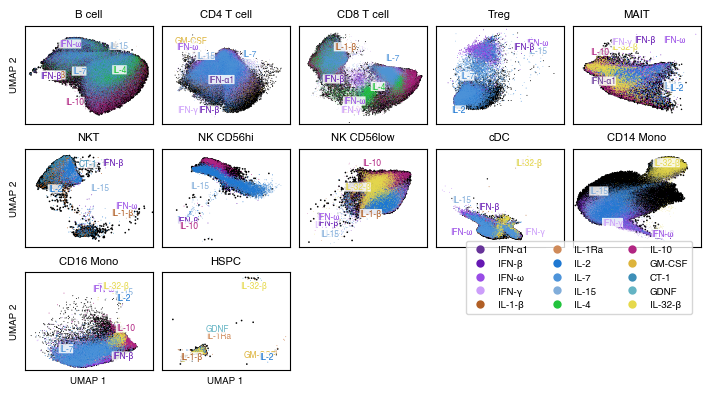

In [21]:
max_points_per_cytokine = 10000
max_points_pbs = 25000
# Create a 5x3 grid for all cell types
fig, axes = plt.subplots(3, 5, figsize=cm_to_inches((18, 10)))
axes = axes.flatten()  # Convert to 1D array for easier indexing

all_used_cytokines = set()
for idx, cell_type in enumerate(ALL_CELL_TYPES):
    print(cell_type)
    if idx >= 15:  # Only plot first 16 cell types for 4x4 grid
        break
        
    ax = axes[idx]
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    
    pbs_data = umap_data[umap_data.obs['cytokine'] == "PBS"]
    pbs_data = pbs_data[pbs_data.obs['cell_type'] == cell_type]
    
    # Subsample PBS data if needed
    if len(pbs_data) > max_points_pbs:
        pbs_data = pbs_data[np.random.choice(len(pbs_data), max_points_pbs, replace=False)]
    
    # Get UMAP coordinates
    umap_coords_pbs = pbs_data.obsm['X_umap']
    cytokines = large_dist[cell_type]
    cytokines = cytokines[cytokines].index.tolist()
    cytokines = [cytokine for cytokine in cytokines if cytokine in allowed_cytokines]
    maximum_cytokines = distances_by_cell_type_raw[cell_type].sort_values(ascending=False).head(8)
    cytokines = [cytokine for cytokine in cytokines if cytokine in maximum_cytokines.index]
    
    ax.scatter(umap_coords_pbs[:, 0], umap_coords_pbs[:, 1], c='black', alpha=1, s=0.5*min(below_max_points, 3), edgecolors="none", rasterized=True)
    for cytokine in cytokines:
        subset_cyto = subset[subset.obs['cytokine'] == cytokine]
        
        # Subsample if needed
        downsampling_rate = max(len(subset_cyto) / max_points_per_cytokine, 1)
        below_max_points = max(1.0, max_points_per_cytokine / len(subset_cyto))
        if len(subset_cyto) > max_points_per_cytokine:
            subset_cyto = subset_cyto[np.random.choice(len(subset_cyto), max_points_per_cytokine, replace=False)]
        if len(subset_cyto) < 50:
            print(f"Skipping {cytokine} because it has less than 50 cells")
            continue
        umap_coords = subset_cyto.obsm['X_umap']
        
        ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=cytokine_colors_hex[cytokine],
                label=cytokine, alpha=1, s=0.1*min(below_max_points, 4), edgecolors="none", rasterized=True)
        all_used_cytokines.add(cytokine)
        # center_x = umap_coords[:, 0].mean()
        # center_y = umap_coords[:, 1].mean()
        # ax.text(center_x, center_y, introduce_greek_letters(cytokine), fontsize=6, ha='center', va='center', 
        #         color=cytokine_colors_hex[cytokine], bbox=dict(boxstyle="round,pad=0.1", facecolor='white', alpha=0.8, edgecolor='none'))
        
    # 1) Precompute all points for this cell type (global) and per-cytokine dict
    all_pts = subset.obsm['X_umap']  # all cytokines (incl PBS) for this cell_type
    cyto_points = {}
    cyto_texts = {}
    for cyto in cytokines:  # your filtered list for this cell_type
        pts = subset[subset.obs['cytokine'] == cyto].obsm['X_umap']
        cyto_points[cyto] = pts
        cyto_texts[cyto] = introduce_greek_letters(cyto)

    # 2) Axis limits already fixed per cell_type:
    xlim = coordinates_by_cell_type[cell_type][0]
    ylim = coordinates_by_cell_type[cell_type][1]

    # 3) Place labels (draws text onto ax)
    _ = place_cytokine_labels_for_celltype(
            ax=ax,
            subset_all_points_xy=all_pts,
            cyto_points_dict=cyto_points,
            cyto_texts=cyto_texts,
            xlim=xlim, ylim=ylim,
            fontsize=6,
            nx=512, ny=512,
            global_sigma=1.8,
            cyto_sigma=1.2,
            dense_quantile=0.80,   # raise if you want labels pushed farther from dense cores
            min_clearance=6,       # in grid pixels; bump to keep labels farther away
            debug=False,
    )    
    
    ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
    ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])
    
    ax.set_xticks([])
    ax.set_yticks([])
    
    # Only label outer axes
    if idx // 5 == 2:  # Bottom row
        ax.set_xlabel('UMAP 1', fontsize=7)
    if idx % 5 == 0:  # Left column
        ax.set_ylabel('UMAP 2', fontsize=7)
    
    ax.set_title(f"{cell_type}", fontsize=8)
    ax.tick_params(labelsize=6)
    
# Hide unused subplots
for idx in range(len(ALL_CELL_TYPES), 15):
    axes[idx].set_visible(False)

# Add a single legend for the entire figure
# Create consistent legend entries manually using the cytokine colors
legend_handles = []
legend_labels = []
for cytokine in cytokine_colors_hex.keys():
    if cytokine not in all_used_cytokines:
        continue
    handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=cytokine_colors_hex[cytokine], 
                       markersize=6, markeredgecolor='none')
    legend_handles.append(handle)
    legend_labels.append(introduce_greek_letters(cytokine))
fig.legend(legend_handles, legend_labels, bbox_to_anchor=(0.65, 0.4), loc='upper left', fontsize=7, ncol=3)

plt.tight_layout()
plt.savefig(os.path.join(plot_folder, f"UMAP_cytokines.svg"), dpi=600)

['D1', 'D3', 'D4', 'D10']
royalblue
['D7', 'D8', 'D12', 'D2', 'D5', 'D6', 'D9', 'D11']
forestgreen


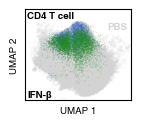

In [17]:
cell_type = "CD4 T cell"
donor_group_1 = ["D1", "D3", "D4", "D10"]
donor_group_2 = [donor for donor in DONOR_NAMES if donor not in donor_group_1]
donor_groups = [donor_group_1, donor_group_2]

max_points_per_cytokine = 10000
cytokines = ["IFN-beta"]
colors = ["royalblue", "forestgreen"]
fig, ax = plt.subplots(figsize=cm_to_inches((3.5, 3)))
for cytokine in cytokines:
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    subset = subset[subset.obs['cytokine'] == "PBS"]
    subset = subset[np.random.choice(len(subset), 50000, replace=False)]
    umap_coords = subset.obsm['X_umap']
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c="lightgray",
        label=",".join(donor_group), alpha=0.1, s=3, edgecolors="none", rasterized=True)
    ax.text(17, 14, "PBS", fontsize=7, fontweight="bold", color='lightgray')
    
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    subset_cyto = subset[subset.obs['cytokine'] == cytokine]
    if len(subset_cyto) > max_points_per_cytokine:
        subset_cyto = subset_cyto[np.random.choice(len(subset_cyto), max_points_per_cytokine, replace=False)]
    for i, donor in enumerate(donor_groups):
        print(donor)
        print(str(colors[i]))
        subset_donors = subset_cyto[subset_cyto.obs['donor'].isin(donor)]
        umap_coords = subset_donors.obsm['X_umap']
        ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=colors[i],
                alpha=0.25, s=0.5, edgecolors="none", rasterized=True)

ax.set_xlim(coordinates_by_cell_type[cell_type][0][0]+1.5, coordinates_by_cell_type[cell_type][0][1]-1.5)
ax.set_ylim(coordinates_by_cell_type[cell_type][1][0]+1.5, coordinates_by_cell_type[cell_type][1][1]-2.5)

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("UMAP 1", fontsize=7)
ax.set_ylabel("UMAP 2", fontsize=7)

ax.text(2, 16, "CD4 T cell", fontsize=7, fontweight="bold", color="black")
ax.text(2, 2, introduce_greek_letters("IFN-beta"), fontsize=7, fontweight="bold", color="black")

# Add legend
# Add a single legend for the entire figure
# Create consistent legend entries manually using the cytokine colors
# legend_handles = []
# legend_labels = []
# for cytokine in cytokine_colors_hex.keys():
#     if cytokine not in cytokines:
#         continue
#     handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=cytokine_colors_hex[cytokine], 
#                        markersize=4, markeredgecolor='none')
#     legend_handles.append(handle)
#     legend_labels.append(introduce_greek_letters(cytokine))
# fig.legend(legend_handles, legend_labels, bbox_to_anchor=(0.65, 0.4), loc='upper left', fontsize=7, ncol=1)
# plt.subplots_adjust(right=0.8)  # Make room for legend

# Enable interactive zoom and pan
plt.savefig(os.path.join(plot_folder, f"UMAP_CD4_T_cell_cytokines.svg"), dpi=400)

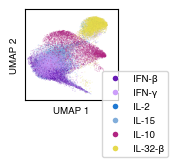

In [23]:
cell_type = "CD14 Mono"
max_points_per_cytokine = 5000
cytokines = ["IL-2", "IL-15", "IFN-beta", "IFN-gamma", "IL-10", "IL-32-beta"]

fig, ax = plt.subplots(figsize=cm_to_inches((3.5, 3)))
for cytokine in cytokines:
    subset = umap_data[umap_data.obs['cell_type'] == cell_type]
    subset_cyto = subset[subset.obs['cytokine'] == cytokine]
    if len(subset_cyto) > max_points_per_cytokine:
        subset_cyto = subset_cyto[np.random.choice(len(subset_cyto), max_points_per_cytokine, replace=False)]
    umap_coords = subset_cyto.obsm['X_umap']
    ax.scatter(umap_coords[:, 0], umap_coords[:, 1], c=cytokine_colors_hex[cytokine],
            alpha=0.25, s=0.5, edgecolors="none", rasterized=True)

ax.set_xlim(coordinates_by_cell_type[cell_type][0][0], coordinates_by_cell_type[cell_type][0][1])
ax.set_ylim(coordinates_by_cell_type[cell_type][1][0], coordinates_by_cell_type[cell_type][1][1])

ax.set_xticks([])
ax.set_yticks([])

ax.set_xlabel("UMAP 1", fontsize=7)
ax.set_ylabel("UMAP 2", fontsize=7)

#ax.text(12, 16, "CD14 Mono", fontsize=7, fontweight="bold", color="black")

# Add legend
# Add a single legend for the entire figure
# Create consistent legend entries manually using the cytokine colors
legend_handles = []
legend_labels = []
for cytokine in cytokine_colors_hex.keys():
    if cytokine not in cytokines:
        continue
    handle = plt.Line2D([0], [0], marker='o', color='w', markerfacecolor=cytokine_colors_hex[cytokine], 
                       markersize=4, markeredgecolor='none')
    legend_handles.append(handle)
    legend_labels.append(introduce_greek_letters(cytokine))
fig.legend(legend_handles, legend_labels, bbox_to_anchor=(0.65, 0.4), loc='upper left', fontsize=7, ncol=1)
plt.subplots_adjust(right=0.8)  # Make room for legend

# Enable interactive zoom and pan
plt.savefig(os.path.join(plot_folder, f"UMAP_CD14_cytokines.svg"), dpi=400)